# How video tracking works

### Key words

| Word | Meaning | Example |
|---|---|---|
| Frame | One image of the video | Frame 0, frame 1, ... |
| Track | One object followed over time | A car from frame 10 to frame 90 |
| ID | The number of a track | `id:7` |
| IoU | Intersection over Union: overlap between two boxes, from 0 to 1 | 1 = identical boxes |
| Matching | Linking boxes of a new frame to existing tracks | Box 3 in frame 1 = track 7 |
| ID switch | A track receives a new ID by mistake | A car changes from `id:7` to `id:12` |
| Kalman filter | Guesses where an object will be next, then corrects the guess with what is seen | Guess 120, seen 124 → 122 |
| Optimal assignment | Pairs old and new boxes in the best way for all boxes together (library `lap`) | 5 cars → 5 correct pairs |
| ByteTrack | A tracker that also uses unsure boxes, to keep half-hidden objects | `tracker="bytetrack.yaml"` |
| BoT-SORT | ByteTrack that also corrects for a moving camera | `tracker="botsort.yaml"` |
| ReID | Re-identification: recognising an object again by how it looks | A car seen again after a bus passes |
| Optical flow | Measuring how pixels move between two frames | Used to correct camera motion |

## 0. Setup
Run this cell once. Expected output: `True`.

In [35]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO

VIDEO = "video_example_1.mp4"
SECONDS = 5 # use only the first 10 seconds
VEHICLES = [2, 3, 5, 7]     # car, motorcycle, bus, truck
model = YOLO("yolo26n.pt")

FPS = cv2.VideoCapture(VIDEO).get(cv2.CAP_PROP_FPS)
FRAMES = int(FPS * SECONDS)

def read_frames(n):
    """Return the first n frames of the video."""
    cap = cv2.VideoCapture(VIDEO)
    frames = [cap.read()[1] for _ in range(n)]
    cap.release()
    return frames


def detect(frame):
    """Return the vehicle boxes of one frame, one row per box: [left, top, right, bottom]."""
    return model(frame, classes=VEHICLES, conf=0.4, verbose=False)[0].boxes.xyxy.numpy()


def draw(frame, tracks):
    """Draw the box and ID of every track that was found in this frame."""
    for track_id, t in tracks.items():
        if t["missed"] == 0:
            x1, y1, x2, y2 = t["box"].astype(int)
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, f"id:{track_id}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return frame


def show_frame(frame, title):
    plt.figure(figsize=(10, 6))
    plt.imshow(frame[:, :, ::-1])  # BGR to RGB colours
    plt.title(title)
    plt.axis("off")
    plt.show()

Using this folder's uv environment: True


## 1. A video is a sequence of images
At 30 frames per second, two frames are 33 ms apart. In that time a vehicle moves only a few pixels.

Time between two frames: 33.3 ms


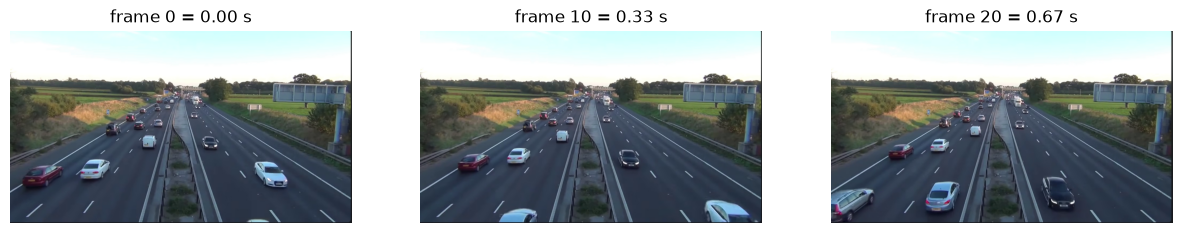

In [36]:
frames = read_frames(21)
print("Time between two frames:", round(1000 / FPS, 1), "ms")

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, i in zip(axes, [0, 10, 20]):
    ax.imshow(frames[i][:, :, ::-1])
    ax.set_title(f"frame {i} = {i / FPS:.2f} s")
    ax.axis("off")
plt.show()

## 2. Detection has no memory
The detector looks at each frame alone. It returns a list of boxes, but no link between frames.

In [37]:
a, b = detect(frames[0]), detect(frames[1])
print("Frame 0:", len(a), "boxes | Frame 1:", len(b), "boxes")
print("First 3 boxes in frame 0:\n", a[:3].round())
print("First 3 boxes in frame 1:\n", b[:3].round())

Frame 0: 8 boxes | Frame 1: 8 boxes
First 3 boxes in frame 0:
 [[         45         500         201         588]
 [        914         489        1038         590]
 [        719         394         781         448]]
First 3 boxes in frame 1:
 [[         59         495         209         581]
 [        720         400         784         455]
 [        269         475         379         550]]


## 3. Idea 1: overlap between two boxes (IoU)

**IoU** (Intersection over Union) = overlap area ÷ combined area.

Example: two 10 × 10 boxes, one moved 5 pixels to the right.
Overlap = 5 × 10 = 50. Combined area = 100 + 100 − 50 = 150. IoU = 50 ÷ 150 = **0.33**.

The same vehicle in two consecutive frames has a **high** IoU, because it moves very little.

In [38]:
def iou(a, b):
    """Overlap of two boxes [left, top, right, bottom]: 0 = no overlap, 1 = identical."""
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    overlap = w * h
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return overlap / (area_a + area_b - overlap)


print("Same box:    ", iou([0, 0, 10, 10], [0, 0, 10, 10]))
print("Moved by 5:  ", round(iou([0, 0, 10, 10], [5, 0, 15, 10]), 2))
print("Far apart:   ", iou([0, 0, 10, 10], [50, 50, 60, 60]))

Same box:     1.0
Moved by 5:   0.33
Far apart:    0.0


IoU between the first 5 boxes of frame 0 (rows) and frame 1 (columns):

In [39]:
table = pd.DataFrame([[iou(x, y) for y in b[:5]] for x in a[:5]]).round(2)
table.index = [f"frame 0, box {i}" for i in table.index]
table.columns = [f"frame 1, box {j}" for j in table.columns]
table

,"frame 1, box 0","frame 1, box 1","frame 1, box 2","frame 1, box 3","frame 1, box 4"
"frame 0, box 0",0.75,0.00,0.00,0.00,0.0
"frame 0, box 1",0.00,0.00,0.00,0.58,0.0
"frame 0, box 2",0.00,0.74,0.00,0.00,0.0
"frame 0, box 3",0.00,0.00,0.72,0.00,0.0
"frame 0, box 4",0.00,0.00,0.00,0.00,0.0


## 4. Idea 2: matching boxes between frames

**Greedy matching:** link the pair with the highest IoU, remove both boxes, repeat. Pairs below 0.3 are not linked.

Real trackers find the best assignment for all boxes at once (the Hungarian method, or the faster Jonker-Volgenant method in the `lap` library).
When vehicles are well separated, both methods give the same result.

In [40]:
def match(old_boxes, new_boxes, min_iou=0.3):
    """Return (old index, new index) pairs, highest overlap first."""
    pairs = sorted(((iou(o, n), i, j) for i, o in enumerate(old_boxes) for j, n in enumerate(new_boxes)), reverse=True)
    links, used_old, used_new = [], set(), set()
    for score, i, j in pairs:
        if score >= min_iou and i not in used_old and j not in used_new:
            links.append((i, j))
            used_old.add(i)
            used_new.add(j)
    return links


links = match(a, b)
print(len(links), "of", len(a), "boxes from frame 0 were found again in frame 1")
print("First links (frame 0 box, frame 1 box):", links[:5])

8 of 8 boxes from frame 0 were found again in frame 1
First links (frame 0 box, frame 1 box): [(5, 4), (6, 5), (7, 7), (4, 6), (0, 0)]


## 5. Idea 3: the life of a track

| Event | Action |
|---|---|
| A new box matches a track | Update the track's box |
| A new box matches no track | Start a new track with a new ID |
| A track matches no box | Count a miss. Delete the track after `max_missed` misses in a row |

Example: a car hidden behind a bus for 5 frames keeps its ID if `max_missed` is 5 or more.

## 6. A complete tracker

The four numbered steps below run on every frame. This is the core of **tracking by detection**.
`step=3` uses only every 3rd frame. `predict` is explained in section 7.

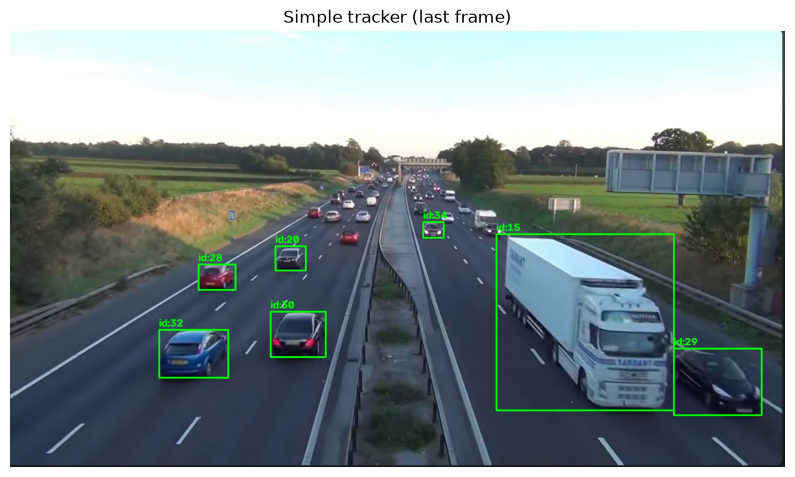

{'IDs': 34, 'frames per ID': np.float64(33.7)}

In [41]:
def simple_tracker(step=1, predict=False, max_missed=10, show=False):
    tracks = {}  # ID -> {"box", "motion", "missed"}
    seen = {}    # ID -> number of frames with a match
    cap = cv2.VideoCapture(VIDEO)
    for f in range(FRAMES):
        ok, frame = cap.read()
        if not ok:
            break
        if f % step:
            continue
        boxes = detect(frame)
        ids = list(tracks)

        # 1) Predict where each track is now
        guesses = [tracks[i]["box"] + (tracks[i]["motion"] if predict else 0) for i in ids]

        # 2) Match the guesses with the new boxes, and update the matched tracks
        links = match(guesses, boxes)
        for i, j in links:
            t = tracks[ids[i]]
            t["motion"], t["box"], t["missed"] = boxes[j] - t["box"], boxes[j], 0
            seen[ids[i]] += 1

        # 3) Tracks without a match: keep the guess, delete after max_missed misses
        for i in set(range(len(ids))) - {i for i, _ in links}:
            tracks[ids[i]]["box"] = guesses[i]
            tracks[ids[i]]["missed"] += 1
            if tracks[ids[i]]["missed"] > max_missed:
                del tracks[ids[i]]

        # 4) Boxes without a match: start new tracks
        for j in set(range(len(boxes))) - {j for _, j in links}:
            new_id = len(seen) + 1
            tracks[new_id] = {"box": boxes[j], "motion": np.zeros(4), "missed": 0}
            seen[new_id] = 1

    cap.release()
    if show:
        show_frame(draw(frame, tracks), "Simple tracker (last frame)")
    return {"IDs": len(seen), "frames per ID": round(np.mean(list(seen.values())), 1)}


simple_tracker(show=True)

## 7. Idea 4: motion prediction

A vehicle moves in a steady way. Its next position can be **predicted** from its last movement:

next box ≈ current box + (current box − previous box)

Example: a car at x = 100, then x = 110. Prediction for the next frame: x = 120.

Real trackers use a **Kalman filter**. It does the same prediction and then **blends** it with the new detection,
according to how much each one is trusted. Example with equal trust:

In [42]:
prediction, detection, trust_in_detection = 120, 124, 0.5
estimate = prediction + trust_in_detection * (detection - prediction)
print("Kalman-style estimate:", estimate)

Kalman-style estimate: 122.0


In Ultralytics, the Kalman filter follows 8 numbers per box: the centre (x, y), the size, and the speed of each. ByteTrack describes the size as width/height ratio and height; BoT-SORT as width and height.

## 8. Experiment: skipped frames, with and without prediction

With `step=3`, vehicles move 3 times further between processed frames, so the overlap drops.
Prediction moves each box forward before matching.

In [43]:
results = {}
for step in [1, 3, 5, 8]:
    for predict in [False, True]:
        results[f"every {step} frame(s), prediction {'on' if predict else 'off'}"] = simple_tracker(step, predict)

pd.DataFrame(results).T

,IDs,frames per ID
"every 1 frame(s), prediction off",34.0,33.7
"every 1 frame(s), prediction on",34.0,33.7
"every 3 frame(s), prediction off",46.0,8.3
"every 3 frame(s), prediction on",25.0,15.3
"every 5 frame(s), prediction off",68.0,3.3
"every 5 frame(s), prediction on",52.0,4.3
"every 8 frame(s), prediction off",71.0,2.0
"every 8 frame(s), prediction on",74.0,1.9


**What to observe:** with `step=3`, compare the number of IDs with and without prediction.
More IDs for the same vehicles means more ID switches.

## 9. How real trackers extend these ideas

| Idea | Simple tracker | Ultralytics setting (ByteTrack / BoT-SORT) |
|---|---|---|
| Minimum overlap to match | `min_iou=0.3` | `match_thresh` |
| Memory of lost tracks | `max_missed=10` | `track_buffer: 30` frames |
| Starting a new track | Any unmatched box | `new_track_thresh` (minimum confidence) |
| Motion | box + last movement | Kalman filter |
| Weak detections | Ignored (`conf=0.4`) | **ByteTrack:** a second matching round with low-confidence boxes (`track_low_thresh`) to recover partly hidden vehicles |
| Moving camera | Not handled | **BoT-SORT:** `gmc_method` corrects camera motion with optical flow |
| Appearance | Not used | **BoT-SORT:** `with_reid` compares how objects look, to re-identify them after occlusion |

The settings file of ByteTrack:

In [44]:
from pathlib import Path
import ultralytics

print((Path(ultralytics.__file__).parent / "cfg" / "trackers" / "bytetrack.yaml").read_text())

# Ultralytics ðŸš€ AGPL-3.0 License - https://ultralytics.com/license

# ByteTrack tracker defaults for mode="track"
# Docs: https://docs.ultralytics.com/modes/track

tracker_type: bytetrack # (str) Tracker backend: bytetrack
track_high_thresh: 0.25 # (float) First-stage match threshold; raise for cleaner tracks, lower to keep more
track_low_thresh: 0.1 # (float) Second-stage threshold for low-score matches; balances recovery vs drift
new_track_thresh: 0.25 # (float) Start a new track if no match â‰¥ this; higher reduces false tracks
track_buffer: 30 # (int) Frames to keep lost tracks alive; higher handles occlusion, increases ID switches risk
match_thresh: 0.8 # (float) Association similarity threshold (IoU/cost); tune with detector quality
fuse_score: True # (bool) Fuse detection score with motion/IoU for matching; stabilizes weak detections



## 10. Comparison with the Ultralytics trackers
Same video and same seconds. Each Ultralytics tracker uses its own thresholds.

In [45]:
def ultralytics_tracker(config):
    tracker_model = YOLO("yolo26n.pt")  # a fresh model for each tracker
    seen = {}
    cap = cv2.VideoCapture(VIDEO)
    for _ in range(FRAMES):
        ok, frame = cap.read()
        if not ok:
            break
        r = tracker_model.track(frame, persist=True, classes=VEHICLES, tracker=config, verbose=False)[0]
        for i in (r.boxes.id.int().tolist() if r.boxes.id is not None else []):
            seen[i] = seen.get(i, 0) + 1
    cap.release()
    return {"IDs": len(seen), "frames per ID": round(np.mean(list(seen.values())), 1)}


pd.DataFrame({
    "simple tracker": simple_tracker(predict=True),
    "ByteTrack": ultralytics_tracker("bytetrack.yaml"),
    "BoT-SORT": ultralytics_tracker("botsort.yaml"),
    "TrackTrack (default)": ultralytics_tracker("tracktrack.yaml"),
}).T

,IDs,frames per ID
simple tracker,34.0,33.7
ByteTrack,32.0,52.7
BoT-SORT,31.0,54.7
TrackTrack (default),16.0,49.2


**What to observe:** the real trackers usually keep IDs longer, thanks to the Kalman filter and the second matching round.
These are simple checks: the true number of vehicles is unknown.

## 11. Summary

**Tracking by detection, on every frame:**
```
frame ─► 1 detect ─► 2 predict ─► 3 match ─► 4 update / create / delete ─► IDs
  ▲                                                                          │
  └──────────────────────────────── next frame ◄─────────────────────────────┘
```

**Other ways to use time in video:**

| Approach | Idea | Examples |
|---|---|---|
| Tracking by detection | Detect in each frame, then link the boxes | ByteTrack, BoT-SORT |
| Optical flow | Follow how pixels move between frames | Camera correction in BoT-SORT |
| Video models with memory | Look at several frames, or keep a memory of each object | Video transformers, SAM 2 |

---
## 12. Watch a real tracker work

`watch()` runs an Ultralytics tracker and draws what the tracker keeps in memory, on every frame.
With `LIVE = True`, a window shows it in real time. Press `q` in the window to stop.

| Step | What happens | What to look at |
|---|---|---|
| 1. Detection | YOLO finds the boxes of the frame | Every box |
| 2. Prediction | The Kalman filter estimates where each track moves | **Yellow arrow** = estimated movement |
| 3. Matching | New boxes are linked to existing tracks | **Green box** keeps the same ID |
| 4. Filtering | Weak boxes start no track. Lost tracks are deleted after 30 frames | The `removed` counter |
| 5. Re-assigning | A lost track that matches again gets its old ID back | A **red box** turns green with the same ID |

**Red box** = lost track: nothing is detected there now, so its position comes from the prediction only.

In [46]:
LIVE = True  # True = show every frame in a window (press q to stop)

def watch(config, video=VIDEO, live=False):
    tracker_model = YOLO("yolo26n.pt")
    seen = {}  # ID -> number of frames
    cap = cv2.VideoCapture(video)
    for _ in range(FRAMES):
        ok, frame = cap.read()
        if not ok:
            break
        tracker_model.track(frame, persist=True, classes=VEHICLES, tracker=config, verbose=False)
        tracker = tracker_model.predictor.trackers[0]  # the tracker and its memory

        for t in tracker.tracked_stracks:  # green: matched tracks
            x1, y1, x2, y2 = t.xyxy.astype(int)
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            vx, vy = t.mean[4:6]  # speed estimated by the Kalman filter, in pixels per frame
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, f"id:{t.track_id}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            cv2.arrowedLine(frame, (cx, cy), (int(cx + 10 * vx), int(cy + 10 * vy)), (0, 255, 255), 2)
            seen[t.track_id] = seen.get(t.track_id, 0) + 1

        for t in tracker.lost_stracks:  # red: lost tracks, moved by prediction only
            x1, y1, x2, y2 = t.xyxy.astype(int)
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(frame, f"lost id:{t.track_id}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

        counts = f"tracked {len(tracker.tracked_stracks)} | lost {len(tracker.lost_stracks)} | removed {len(tracker.removed_stracks)}"
        cv2.putText(frame, counts, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2)
        cv2.putText(frame, f"{video} | {config}", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2)
        if live:
            cv2.imshow("Tracker memory (press q to stop)", frame)
            if cv2.waitKey(1) == ord("q"):
                break
    cap.release()
    cv2.destroyAllWindows()
    if live:
        show_frame(frame, f"{config} (last frame)")
        t = tracker.tracked_stracks[0]
        print(f"Kalman numbers of id:{t.track_id}:", t.mean.round(1))
    return {"IDs": len(seen), "frames per ID": round(np.mean(list(seen.values())), 1)}

# pd.DataFrame({"ByteTrack": watch("bytetrack.yaml", live=LIVE), "BoT-SORT": watch("botsort.yaml", live=LIVE)}).T

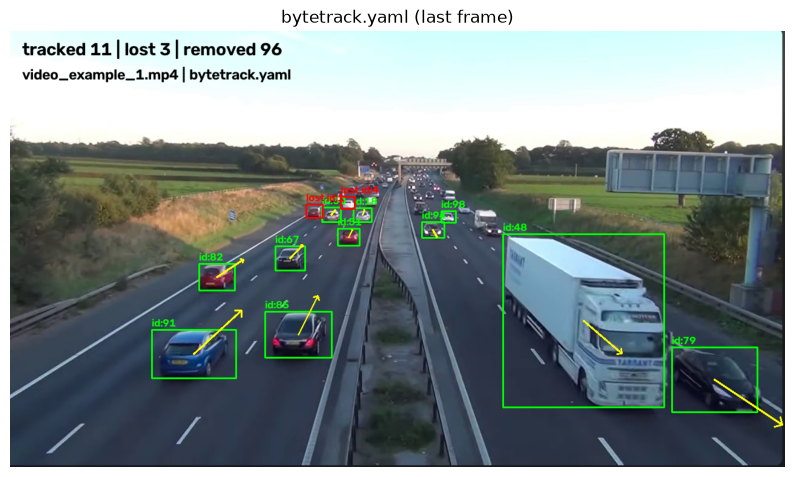

Kalman numbers of id:18: [      582.6       304.2         1.3        22.4         0.4        -0.7          -0           0]


,IDs,frames per ID
ByteTrack,98.0,18.1


In [47]:
outputs =  watch("bytetrack.yaml", live=LIVE)
pd.DataFrame({"ByteTrack": outputs}).T

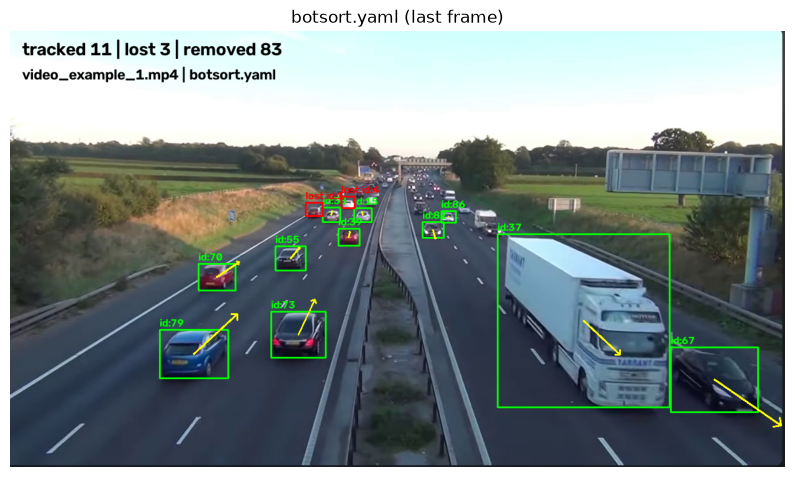

Kalman numbers of id:15: [      582.7       304.1        29.1        22.4        -0.1        -0.5        -0.1           0]


,IDs,frames per ID
BoT-SORT,86.0,20.6


In [48]:
outputs =  watch("botsort.yaml", live=LIVE)
pd.DataFrame({"BoT-SORT": outputs}).T

## 13. Camera movement: with and without correction

If the camera moves, every box shifts at once and the predictions become wrong.
BoT-SORT can measure the camera movement between two frames and correct for it (`gmc_method`).

First, how much does the camera move in each video? The value is the average shift of the whole picture, in pixels per frame.

In [49]:
from ultralytics.trackers.utils.gmc import GMC


def camera_movement(video):
    gmc, shifts = GMC(method="sparseOptFlow"), []
    cap = cv2.VideoCapture(video)
    for _ in range(FRAMES):
        ok, frame = cap.read()
        if not ok:
            break
        move = gmc.apply(frame)  # 2 x 3 table; the last column is the shift in x and y
        shifts.append(np.hypot(move[0, 2], move[1, 2]))
    cap.release()
    return round(float(np.mean(shifts)), 2)


for video in ["video_example_1.mp4", "video_example_2.mp4"]:
    print(video, "camera movement:", camera_movement(video), "pixels per frame")

video_example_1.mp4 camera movement: 0.97 pixels per frame
video_example_2.mp4 camera movement: 0.2 pixels per frame


Now BoT-SORT on both videos, with the correction on (default) and off. With `LIVE = True`, the four cases play one after another in the window, and the video name and settings file are written at the top.
The "off" settings are a copy of `botsort.yaml` with `gmc_method: none`, saved in `outputs`.

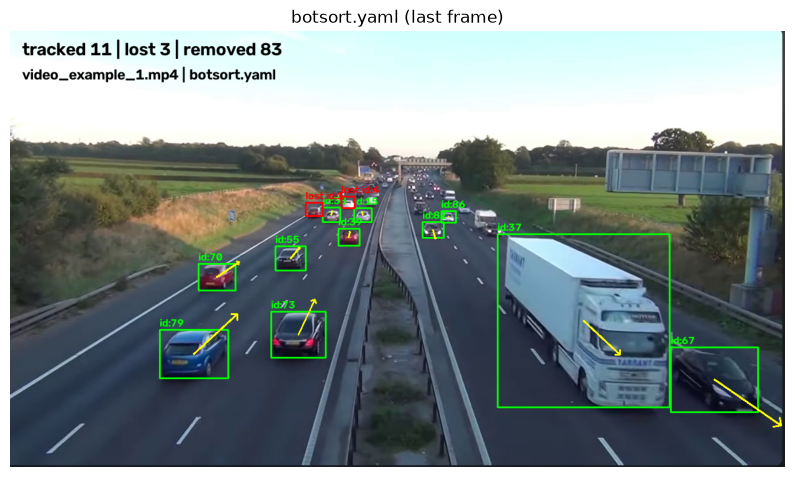

Kalman numbers of id:15: [      582.7       304.1        29.1        22.4        -0.1        -0.5        -0.1           0]


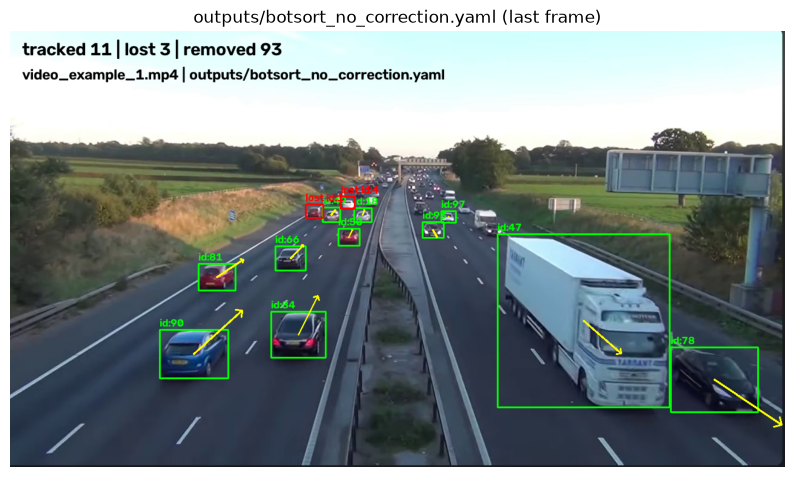

Kalman numbers of id:18: [      582.6       304.2        29.1        22.4         0.4        -0.7        -0.1           0]


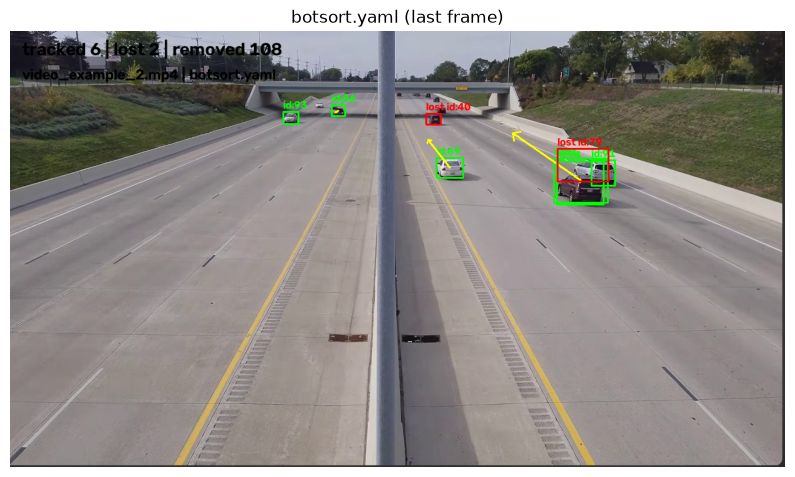

Kalman numbers of id:69: [      726.2       225.9        43.7        33.2        -3.5        -4.6        -1.7        -1.4]


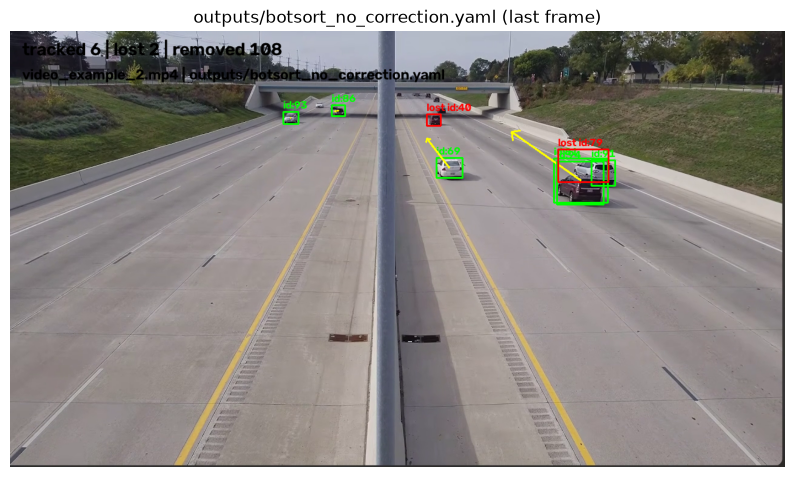

Kalman numbers of id:69: [      726.1       225.9        43.7        33.2        -3.6        -4.8        -1.7        -1.4]


,IDs,frames per ID
"video_example_1.mp4, correction on",86.0,20.6
"video_example_1.mp4, correction off",97.0,18.2
"video_example_2.mp4, correction on",94.0,10.8
"video_example_2.mp4, correction off",94.0,10.8


In [52]:
from pathlib import Path
import ultralytics
from ultralytics.utils import YAML

settings = YAML.load(Path(ultralytics.__file__).parent / "cfg" / "trackers" / "botsort.yaml")
settings["gmc_method"] = "none"
Path("outputs").mkdir(exist_ok=True)
YAML.save("outputs/botsort_no_correction.yaml", settings)

rows = {}
for video in ["video_example_1.mp4", "video_example_2.mp4"]:
    rows[f"{video}, correction on"] = watch("botsort.yaml", video, live=LIVE)
    rows[f"{video}, correction off"] = watch("outputs/botsort_no_correction.yaml", video, live=LIVE)
pd.DataFrame(rows).T